Analyst's prediction (written before results): after the 2015 franc shock, luxury resorts lost more German nights than their mid-range neighbours (in particular, St. Moritz more than Scuol); the most vulnerable canton is Graubünden, home of St. Moritz.

## Rules (fixed before any result was computed; committed on their own before the analysis)

### A. Which cantons are most vulnerable to the franc?
- **Exposure:** share of each canton's nights from euro markets (Germany, France, Italy), 2016-2019. The canton total is the 7 tracked markets (the source has no all-guests total).
- **Sensitivity:** the notebook 02 YoY design per canton: YoY log change of the canton's euro nights (DE + FR + IT summed) on the YoY log change of CHF per EUR **at lag 6**; same sample rule as notebook 02 (all lags 0-12 available, no covid month in t or t-12), OLS with Newey-West SE (12 lags), 95% CI = estimate ± 1.96 SE. Check: the same code on German nights in the 7 cantons must reproduce the notebook 02 coefficient 0.63.
- **Vulnerability** = expected % change in the canton's total nights for a 10% stronger franc = 100 × exposure × (0.9^β - 1), with the interval from β's 95% CI (exposure treated as fixed).
- **Verdict:** the "most vulnerable" canton is the first by point estimate; it is "clearly separated" only if its interval does not overlap the second canton's interval, otherwise "ranking not clearly separated".
- **Cross-check (descriptive, no threshold):** `fx_scenarios`, EUR only, -10%: each canton's 12-month total nights (canton x origin series) vs the 0% scenario. Report the Spearman rank correlation with the vulnerability ranking (7 cantons) and whether both put the same canton first.

### B. Luxury vs mid-range after 2015 (4 pairs, commune level)
- **Pairs:** St. Moritz-Scuol, Klosters-Tujetsch, Zermatt-Saas-Grund, Saanen (Gstaad)-Lenk.
- **Index:** German nights Jul 2015 - Dec 2016 / German nights in the same calendar months of 2014 (Jul-Dec 2014 + Jan-Dec 2014) × 100. Same months on both sides, so seasonality cancels. Jan-Jun 2015 are left out: the winter season was booked before the 15 Jan 2015 shock.
- **Gap** = German index - Swiss index in the same resort (index points), so shocks that hit the resort for all guests cancel out.
- **Verdict:** in a pair, luxury "fell more" if its gap is lower than its mid-range neighbour's. "Luxury lost more" only if this holds in at least 3 of the 4 pairs; otherwise "no consistent pattern". St. Moritz vs Scuol is reported on its own. A 4-case study, not a statistical test.
- **Context only (not part of the verdict):** the same gap for 2014 vs 2013 (before the shock).
- **Hypothesis being tested:** Blengini, I. and Heo, C. (2019), *How did SNB exchange rate interventions impact Hotel performance in Switzerland?*, 3rd Revenue Management & Pricing in Services Conference, Lausanne (EHL, HES-SO), https://arodes.hes-so.ch/record/6832. Their abstract: hoteliers react to franc appreciations more strongly in economy and midscale classes than in upper classes, and appreciations reduce occupancy only for luxury hotels.
- **Limits:** data start in 2013 (only 2 years before the shock); we see volumes (nights), not prices or occupancy.

### C. What is the model worth in seasonal staff?
- **Peak season** of each canton: its 3 highest months by average share of annual nights, 2013-2019 (`seasonal_profile`, canton total).
- **Errors:** post-covid backtest at h = 6 (43 target months, Jan 2023 - Jul 2026); canton total = sum of its 7 canton x origin series; in the canton's peak months only. Mean absolute error (nights per month) of the seasonal naive and of (naive + model with FX) / 2.
- **Gain** = MAE(naive) - MAE(combination), nights per peak month (positive = the combination is closer); also as a % of the canton's average actual peak-month nights in the same months.
- **Staff (assumption, not a fact):** 40 to 180 hotel nights per seasonal full-time employee per month, from 0.3 (mid-range) to 1.5 (luxury) staff per room, 1.8 guests per occupied room and full occupancy in peak (30 days × 1.8 / 1.5 = 36 ≈ 40; 30 × 1.8 / 0.3 = 180). Staff equivalent = gain / 180 to gain / 40, for the whole canton, all hotels together. Always labelled as an illustration under this assumption.

Descriptive language only: nothing here measures a causal effect of the franc.

## Summary (Sprint 5: the original questions)

**The prediction holds for cantons, not for resorts.** Graubünden ranks first for vulnerability, although its interval overlaps Valais. The luxury-vs-mid-range claim is not established: the pre-set rule says "luxury lost more" (3 of 4 pairs), but one of the three rests on a series broken by a municipal merger. Without that pair, luxury fell more in 2 of 3, short of the pre-set 3-pair threshold.

**A. Vulnerability to a 10% stronger franc** (expected change in the canton's nights, 95% CI):
- **Graubünden: -2.2% (-3.2 to -1.1)**, first of 7. Its euro share is 22.5% and its sensitivity is the highest (beta 0.96). Second is Valais at -1.3% (-1.9 to -0.6); the intervals overlap, so the ranking is **not clearly separated**.
- **Geneva has the most euro guests (27.6%)** but a lower sensitivity (beta 0.31), so it ranks 4th at -0.9%.
- **4 of 7 cantons have a beta interval that excludes 0.** Lucerne, Zurich and Vaud do not.
- **The check runs the same code on German nights in all 7 cantons** and reproduces the notebook 02 coefficient, 0.63.
- **Cross-check with the forecast model** (`fx_scenarios`, EUR only, -10%): Graubünden is also first (-0.9% over 12 months), and the Spearman rank correlation is 0.54.

**B. Luxury vs mid-range after 2015** (German index minus Swiss index, Jul 2015 - Dec 2016 vs the same months of 2014):
- **Klosters - Tujetsch:** -29.0 vs -17.7, luxury fell more.
- **Zermatt - Saas-Grund:** -26.9 vs -18.6, luxury fell more.
- **Saanen - Lenk:** -26.0 vs -28.0, mid-range fell more.
- **St. Moritz - Scuol: not comparable.** Scuol merged with five villages on 1 Jan 2015, and its German index is 383, against 62-91 in the other resorts. This was found after the results; the pre-set verdict is kept as computed and shown next to this check.
- **Hypothesis tested:** Blengini and Heo (2019, EHL / HES-SO) found that a stronger franc reduced occupancy only in luxury hotels. Our volumes point the same way in 2 of 3 comparable pairs, but 3 pairs are too few, and we see neither prices nor occupancy.

**C. Model gain in seasonal staff** (h = 6, canton peak months, post-covid; an illustration under an assumption):
- **The combination's error is lower in 6 of 7 cantons,** by -0.08% to +2.17% of peak-month nights.
- **Largest gain: Lucerne,** with 4,216 fewer nights of error per peak month (2.17%), about 23-105 seasonal FTE.
- **Graubünden: no gain** (-520 nights, -0.08%).
- **All 7 cantons together:** 13,912 nights per peak month, about **77-348 FTE**. This assumes 40-180 nights per seasonal FTE per month; the range comes from that assumption, not from data.

Every number above is checked by the last code cell ("Summary check").


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import GREY, INK_SOFT, ORIGIN_COLORS, SLOTS, SOURCE_BFS, SOURCE_BFS_SNB, add_source, connect, save, set_style
import forecast as fc
import fx_effect as fe
import long_horizon as lh
import original_questions as oq
import outlook as ol

set_style()
pd.set_option("display.precision", 3)
con = connect()
panel, fx = fc.load_panel(con), fc.load_fx_yoy(con)

## A. Which cantons are most vulnerable to the franc?

Check first: the same code on German nights in the 7 cantons must reproduce the notebook 02 coefficient at lag 6.

In [2]:
n = oq.canton_nights(con)
de_total = n[n["origin"] == "Germany"].groupby("date")["nights"].sum().asfreq("MS")
de = oq.fx_sensitivity(de_total, oq.eur_chf(con))
assert round(de["beta"], 2) == 0.63
print(f"Germany, 7 cantons, lag 6: beta {de['beta']:.2f} (95% CI {de['beta_lo']:.2f} to {de['beta_hi']:.2f}), N = {de['N']} "
      f"-> reproduces notebook 02")

Germany, 7 cantons, lag 6: beta 0.63 (95% CI 0.28 to 0.98), N = 194 -> reproduces notebook 02


In [3]:
v = oq.vulnerability(con)
display(v[["rank", "canton", "exposure", "beta", "beta_lo", "beta_hi", "p", "N", "vuln_pct", "vuln_lo", "vuln_hi"]].round(3))
first, second = v.iloc[0], v.iloc[1]
print(f"Most exposed: {v.loc[v['exposure'].idxmax(), 'canton']} ({100 * v['exposure'].max():.1f}% euro nights); "
      f"least: {v.loc[v['exposure'].idxmin(), 'canton']} ({100 * v['exposure'].min():.1f}%)")
print(f"Most vulnerable: {first.canton} {first.vuln_pct:+.1f}% (95% CI {first.vuln_lo:+.1f} to {first.vuln_hi:+.1f}); "
      f"second: {second.canton} {second.vuln_pct:+.1f}% ({second.vuln_lo:+.1f} to {second.vuln_hi:+.1f})")
print("Verdict A:", oq.verdict_a(v))
gr = v.set_index("canton").loc["Graubünden"]
print(f"Graubünden: rank {int(gr['rank'])} of 7, {gr.vuln_pct:+.1f}% ({gr.vuln_lo:+.1f} to {gr.vuln_hi:+.1f}), "
      f"exposure {100 * gr.exposure:.1f}%, beta {gr.beta:.2f}")
print(f"Cantons whose beta CI excludes 0: {v.loc[v['beta_lo'] > 0, 'canton'].tolist()}")

,rank,canton,exposure,beta,beta_lo,beta_hi,p,N,vuln_pct,vuln_lo,vuln_hi
0,1,Graubünden,0.225,0.963,0.465,1.461,0.000,194,-2.172,-3.212,-1.075
1,2,Valais,0.172,0.734,0.363,1.105,0.000,194,-1.280,-1.890,-0.645
2,3,Bern,0.157,0.548,0.240,0.857,0.000,194,-0.879,-1.351,-0.391
3,4,Geneva,0.276,0.306,0.041,0.571,0.024,194,-0.876,-1.613,-0.118
4,5,Lucerne,0.167,0.388,-0.048,0.824,0.081,194,-0.668,-1.386,0.084
5,6,Zurich,0.255,0.220,-0.201,0.641,0.306,194,-0.582,-1.662,0.546
6,7,Vaud,0.237,0.223,-0.152,0.598,0.244,194,-0.550,-1.447,0.382


Most exposed: Geneva (27.6% euro nights); least: Bern (15.7%)
Most vulnerable: Graubünden -2.2% (95% CI -3.2 to -1.1); second: Valais -1.3% (-1.9 to -0.6)
Verdict A: Graubünden: ranking not clearly separated
Graubünden: rank 1 of 7, -2.2% (-3.2 to -1.1), exposure 22.5%, beta 0.96
Cantons whose beta CI excludes 0: ['Graubünden', 'Valais', 'Bern', 'Geneva']


### Cross-check with the forecast model (`fx_scenarios`, EUR only, -10%)

In [4]:
models = lh.forecast_from_origin(panel, fx)
scen = oq.scenario_by_canton(models)
cc = oq.cross_check(v, scen)
display(v.set_index("canton")[["vuln_pct"]].join(scen).assign(rank_scenario=lambda d: d["scenario_pct"].rank()).round(2))
print(f"Spearman rank correlation (7 cantons): {cc['spearman']:.2f} | first by vulnerability: {cc['first_vuln']}, "
      f"first by scenario: {cc['first_scenario']}")

,vuln_pct,scenario_pct,rank_scenario
canton,,,
Graubünden,-2.17,-0.87,1.0
Valais,-1.28,-0.60,2.0
Bern,-0.88,-0.33,6.0
Geneva,-0.88,-0.46,4.0
Lucerne,-0.67,-0.34,5.0
Zurich,-0.58,-0.33,7.0
Vaud,-0.55,-0.58,3.0


Spearman rank correlation (7 cantons): 0.54 | first by vulnerability: Graubünden, first by scenario: Graubünden


### Chart 19 — Vulnerability ranking

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/19_canton_vulnerability.png')

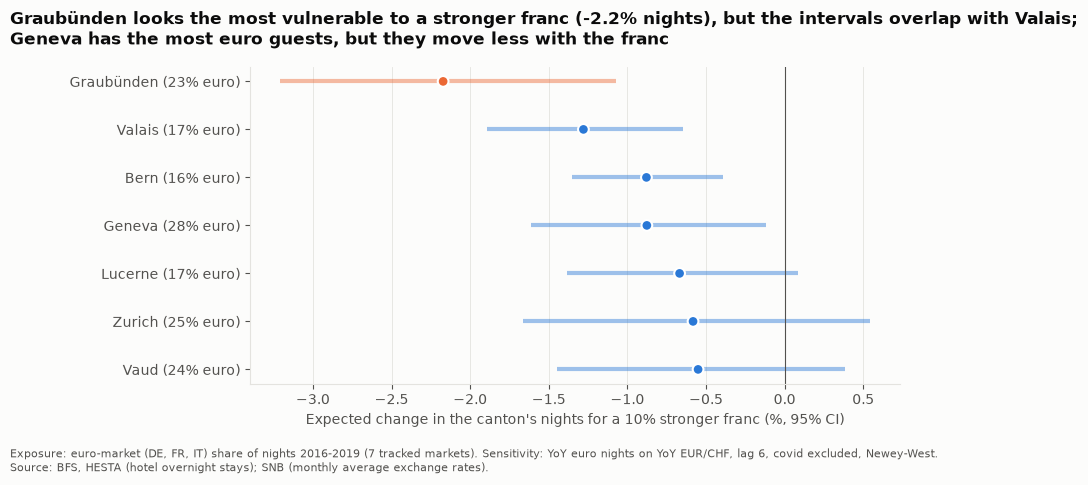

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(v))[::-1]
col = [SLOTS[1] if c == "Graubünden" else SLOTS[0] for c in v["canton"]]
ax.hlines(y, v["vuln_lo"], v["vuln_hi"], color=col, lw=3, alpha=0.45)
ax.scatter(v["vuln_pct"], y, color=col, s=60, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(0, color=INK_SOFT, lw=0.8)
ax.set_yticks(y, [f"{c} ({100 * e:.0f}% euro)" for c, e in zip(v["canton"], v["exposure"])])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Expected change in the canton's nights for a 10% stronger franc (%, 95% CI)")
sep = "clearly ahead" if "clearly" in oq.verdict_a(v) and "not" not in oq.verdict_a(v) else "but the intervals overlap"
most_exp = v.loc[v["exposure"].idxmax(), "canton"]
fig.suptitle(f"{first.canton} looks the most vulnerable to a stronger franc ({first.vuln_pct:+.1f}% nights), {sep} with {second.canton};\n"
             f"{most_exp} has the most euro guests, but they move less with the franc", x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Exposure: euro-market (DE, FR, IT) share of nights 2016-2019 (7 tracked markets). "
           "Sensitivity: YoY euro nights on YoY EUR/CHF, lag 6, covid excluded, Newey-West.")
fig.subplots_adjust(left=0.25, bottom=0.2, top=0.86)
save(fig, "19_canton_vulnerability")

## B. Luxury vs mid-range after the 2015 shock (4 pairs)

In [6]:
idx, pairs = oq.resort_pairs(con)
display(idx.round(1))
display(pairs.round(1))
print(f"Luxury fell more in {int(pairs['luxury_fell_more'].sum())} of 4 pairs -> verdict B: {oq.verdict_b(pairs)}")
for _, p in pairs.iterrows():
    print(f"{p.pair}: German index {p.de_index_luxury:.1f} vs {p.de_index_mid:.1f}; gap (DE - CH) {p.gap_luxury:+.1f} vs "
          f"{p.gap_mid:+.1f} -> {'luxury fell more' if p.luxury_fell_more else 'mid-range fell more'} "
          f"(2014 vs 2013 context: {p.gap_ctx_luxury:+.1f} vs {p.gap_ctx_mid:+.1f})")

,geo,origin,nights_post,nights_base_2014,index_post,index_2014_vs_2013,resort_type
0,Klosters,Germany,36851.0,59412.0,62.0,81.0,luxury
1,Klosters,Switzerland,85963.0,94453.0,91.0,88.9,luxury
2,Lenk,Germany,6563.0,8328.0,78.8,86.3,mid-range
3,Lenk,Switzerland,144144.0,134967.0,106.8,101.8,mid-range
4,Saanen,Germany,19534.0,27027.0,72.3,93.0,luxury
5,Saanen,Switzerland,282632.0,287712.0,98.2,105.2,luxury
6,Saas-Grund,Germany,9842.0,13497.0,72.9,103.0,mid-range
7,Saas-Grund,Switzerland,34632.0,37856.0,91.5,120.3,mid-range
8,Scuol,Germany,70640.0,18443.0,383.0,91.6,mid-range
9,Scuol,Switzerland,281430.0,231977.0,121.3,99.9,mid-range


,pair,luxury,mid_range,de_index_luxury,de_index_mid,gap_luxury,gap_mid,gap_ctx_luxury,gap_ctx_mid,luxury_fell_more,difference,comparable
0,St. Moritz - Scuol,St. Moritz,Scuol,85.2,383.0,-11.6,261.7,-1.5,-8.3,True,-273.3,False
1,Klosters - Tujetsch,Klosters,Tujetsch,62.0,90.8,-29.0,-17.7,-7.9,-5.3,True,-11.3,True
2,Zermatt - Saas-Grund,Zermatt,Saas-Grund,77.4,72.9,-26.9,-18.6,0.2,-17.3,True,-8.4,True
3,Saanen - Lenk,Saanen,Lenk,72.3,78.8,-26.0,-28.0,-12.3,-15.5,False,2.0,True


Luxury fell more in 3 of 4 pairs -> verdict B: luxury lost more
St. Moritz - Scuol: German index 85.2 vs 383.0; gap (DE - CH) -11.6 vs +261.7 -> luxury fell more (2014 vs 2013 context: -1.5 vs -8.3)
Klosters - Tujetsch: German index 62.0 vs 90.8; gap (DE - CH) -29.0 vs -17.7 -> luxury fell more (2014 vs 2013 context: -7.9 vs -5.3)
Zermatt - Saas-Grund: German index 77.4 vs 72.9; gap (DE - CH) -26.9 vs -18.6 -> luxury fell more (2014 vs 2013 context: +0.2 vs -17.3)
Saanen - Lenk: German index 72.3 vs 78.8; gap (DE - CH) -26.0 vs -28.0 -> mid-range fell more (2014 vs 2013 context: -12.3 vs -15.5)


### Data-validity check (added after seeing the results, not a rule change)

Scuol's German index (383) is far outside the other resorts (62-91). Scuol **merged with Ardez, Ftan, Guarda, Sent and Tarasp on 1 Jan 2015** (canton of Graubünden; Historical Dictionary of Switzerland), two weeks before the franc shock, so its 2014 base covers a smaller area than 2015-2016. The Swiss-guest gap cannot cancel this, because the new villages had a different guest mix. The St. Moritz - Scuol pair is therefore **not comparable**; the pre-set verdict above is kept as computed, and the same 3-pair threshold is shown on the comparable pairs only.

In [7]:
annual = con.sql("""SELECT year(date) AS year, origin, SUM(nights) AS nights FROM monthly_nights
    WHERE level = 'commune' AND geo = 'Scuol' AND origin IN ('Germany', 'Switzerland')
      AND year(date) BETWEEN 2013 AND 2017 GROUP BY ALL""").df().pivot(index="year", columns="origin", values="nights")
display((100 * annual / annual.loc[2014]).round(0).rename(columns=lambda c: f"{c} (2014 = 100)"))
other = idx[(idx["origin"] == "Germany") & (idx["geo"] != "Scuol")]["index_post"]
print(f"Scuol German index {idx.set_index(['geo', 'origin']).loc[('Scuol', 'Germany'), 'index_post']:.0f} vs "
      f"{other.min():.0f}-{other.max():.0f} in the other 7 resorts")
print("Pre-set verdict B (4 pairs):", oq.verdict_b(pairs))
print("Comparable pairs only:", oq.verdict_b_comparable(pairs))

origin,Germany (2014 = 100),Switzerland (2014 = 100)
year,,
2013,109.0,100.0
2014,100.0,100.0
2015,542.0,122.0
2016,294.0,120.0
2017,158.0,133.0


Scuol German index 383 vs 62-91 in the other 7 resorts
Pre-set verdict B (4 pairs): luxury lost more
Comparable pairs only: not established (2 of 3 comparable pairs)


### Chart 20 — German-minus-Swiss gap per pair

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/20_resort_pairs.png')

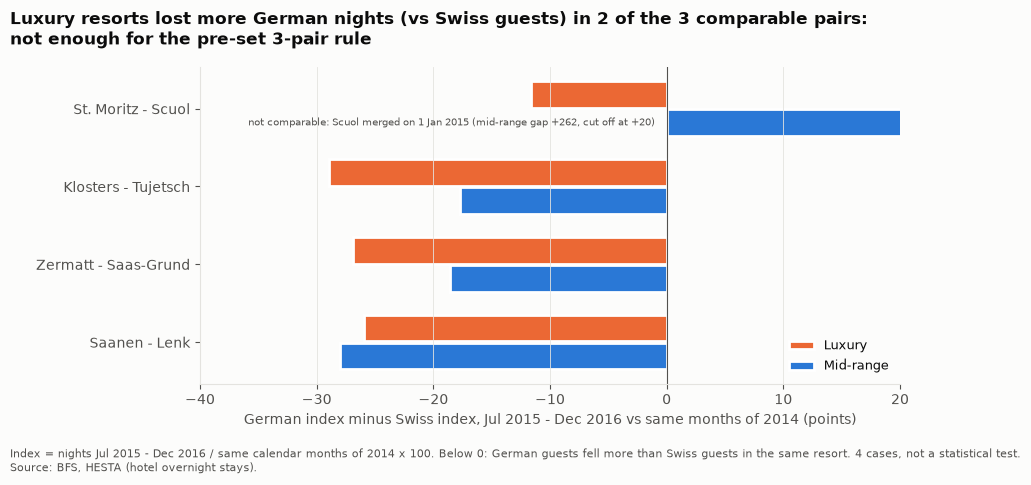

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(pairs))[::-1]
ax.barh(y + 0.18, pairs["gap_luxury"], height=0.34, color=SLOTS[1], label="Luxury", edgecolor="white", linewidth=2)
ax.barh(y - 0.18, pairs["gap_mid"], height=0.34, color=SLOTS[0], label="Mid-range", edgecolor="white", linewidth=2)
ax.axvline(0, color=INK_SOFT, lw=0.8)
XMAX = 20      # Scuol's gap (merger in 2015) would hide the other pairs
ax.set_xlim(-40, XMAX)
for yy, (_, p) in zip(y, pairs.iterrows()):
    if not p["comparable"]:
        ax.annotate(f"not comparable: Scuol merged on 1 Jan 2015 (mid-range gap {p.gap_mid:+.0f}, cut off at +{XMAX})",
                    xy=(-1, yy - 0.18), ha="right", va="center", fontsize=7.5, color=INK_SOFT)
ax.set_yticks(y, pairs["pair"]); ax.grid(axis="y", visible=False)
ax.set_xlabel("German index minus Swiss index, Jul 2015 - Dec 2016 vs same months of 2014 (points)")
ax.legend(loc="lower right", fontsize=9)
k = int(pairs["luxury_fell_more"].sum())
ok = pairs[pairs["comparable"]]
fig.suptitle(f"Luxury resorts lost more German nights (vs Swiss guests) in {int(ok['luxury_fell_more'].sum())} of the "
             f"{len(ok)} comparable pairs:\nnot enough for the pre-set 3-pair rule", x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS + ".", "Index = nights Jul 2015 - Dec 2016 / same calendar months of 2014 x 100. "
           "Below 0: German guests fell more than Swiss guests in the same resort. 4 cases, not a statistical test.")
fig.subplots_adjust(left=0.2, bottom=0.2, top=0.86)
save(fig, "20_resort_pairs")

## C. What is the model worth in seasonal staff? (illustration under an assumption)

In [9]:
res = ol.load_backtest(panel)
st = oq.staff_gain(res, con)
display(st.round(1))
lo, hi = oq.NIGHTS_PER_STAFF
for _, r in st.iterrows():
    print(f"{r.canton} ({r.peak_months}, {int(r.n_months)} months): MAE naive {r.mae_naive:,.0f} vs combination "
          f"{r.mae_combo:,.0f} nights/month -> gain {r.gain_nights:+,.0f} ({r.gain_pct_of_peak:+.2f}% of "
          f"{r.mean_actual:,.0f}) ~ {r.staff_low:+.0f} to {r.staff_high:+.0f} FTE per peak month")
print(f"Combination better in {int((st['gain_nights'] > 0).sum())} of 7 cantons; gain from "
      f"{st['gain_pct_of_peak'].min():+.2f}% to {st['gain_pct_of_peak'].max():+.2f}% of peak-month nights; "
      f"all 7 together {st['gain_nights'].sum():+,.0f} nights/month ~ {st['staff_low'].sum():+.0f} to "
      f"{st['staff_high'].sum():+.0f} FTE (assumption: {lo}-{hi} nights per seasonal FTE per month)")

,canton,peak_months,n_months,mean_actual,mae_naive,mae_combo,gain_nights,gain_pct_of_peak,staff_low,staff_high
0,Bern,"Jul, Aug, Sep",10,535553.2,21803.3,19529.5,2273.8,0.4,12.6,56.8
1,Geneva,"Mar, Jun, Jul",12,213269.7,16088.3,13413.9,2674.4,1.3,14.9,66.9
2,Graubünden,"Jan, Feb, Mar",12,612493.4,41160.1,41680.1,-520.0,-0.1,-2.9,-13.0
3,Lucerne,"Jul, Aug, Sep",10,194405.1,8559.7,4344.2,4215.5,2.2,23.4,105.4
4,Valais,"Feb, Mar, Aug",11,410649.7,15949.9,15701.1,248.8,0.1,1.4,6.2
5,Vaud,"Jul, Aug, Sep",10,251784.9,11448.8,8386.3,3062.5,1.2,17.0,76.6
6,Zurich,"Jun, Jul, Aug",11,461600.6,24972.7,23016.1,1956.7,0.4,10.9,48.9


Bern (Jul, Aug, Sep, 10 months): MAE naive 21,803 vs combination 19,529 nights/month -> gain +2,274 (+0.42% of 535,553) ~ +13 to +57 FTE per peak month
Geneva (Mar, Jun, Jul, 12 months): MAE naive 16,088 vs combination 13,414 nights/month -> gain +2,674 (+1.25% of 213,270) ~ +15 to +67 FTE per peak month
Graubünden (Jan, Feb, Mar, 12 months): MAE naive 41,160 vs combination 41,680 nights/month -> gain -520 (-0.08% of 612,493) ~ -3 to -13 FTE per peak month
Lucerne (Jul, Aug, Sep, 10 months): MAE naive 8,560 vs combination 4,344 nights/month -> gain +4,216 (+2.17% of 194,405) ~ +23 to +105 FTE per peak month
Valais (Feb, Mar, Aug, 11 months): MAE naive 15,950 vs combination 15,701 nights/month -> gain +249 (+0.06% of 410,650) ~ +1 to +6 FTE per peak month
Vaud (Jul, Aug, Sep, 10 months): MAE naive 11,449 vs combination 8,386 nights/month -> gain +3,063 (+1.22% of 251,785) ~ +17 to +77 FTE per peak month
Zurich (Jun, Jul, Aug, 11 months): MAE naive 24,973 vs combination 23,016 nights/mon

## Verdict on the analyst's prediction

In [10]:
claims = {
    "Luxury lost more German nights than mid-range": (
        f"pre-set rule: {oq.verdict_b(pairs)} (3 of 4 pairs); comparable pairs only: {oq.verdict_b_comparable(pairs)}"
        " -> NOT ESTABLISHED"),
    "St. Moritz lost more than Scuol": "CANNOT BE ASSESSED (Scuol merged on 1 Jan 2015; the pre-set rule says yes)",
    "Graubünden is the most vulnerable canton": (
        f"SUPPORTED, but {oq.verdict_a(v).split(': ')[1]} (overlaps {second.canton}); "
        f"also first in the fx_scenarios cross-check" if first.canton == "Graubünden" else "NOT SUPPORTED"),
}
for c, verdict in claims.items():
    print(f"{c}: {verdict}")

Luxury lost more German nights than mid-range: pre-set rule: luxury lost more (3 of 4 pairs); comparable pairs only: not established (2 of 3 comparable pairs) -> NOT ESTABLISHED
St. Moritz lost more than Scuol: CANNOT BE ASSESSED (Scuol merged on 1 Jan 2015; the pre-set rule says yes)
Graubünden is the most vulnerable canton: SUPPORTED, but ranking not clearly separated (overlaps Valais); also first in the fx_scenarios cross-check


## Limitations

- **A:** the canton total is the 7 tracked markets, not all guests. One FX lag (6) and one currency (EUR) per canton; non-euro markets are assumed not to move with EUR/CHF. Exposure is treated as fixed (2016-2019). Associations, not causal effects.
- **B:** the St. Moritz - Scuol pair is broken by the Scuol merger of 1 Jan 2015 (found after the results), leaving 3 comparable pairs; 4 pairs at most, no statistical test; data start in 2013, only 2 years before the shock; volumes (nights), not prices or occupancy, so the HES-SO price channel cannot be seen. The Swiss guests are not a clean control (a strong franc also makes holidays abroad cheaper for them).
- **C:** the staff numbers rest on an assumed 40-180 nights per seasonal FTE per month, not on data. They describe the whole canton's hotels together; a gain at canton level does not mean each hotel gains. About 10-11 peak months per canton in one post-covid period.
- Hotels only (HESTA).

## Summary check

Every number in the summary at the top must match the results above.

In [11]:
f1 = lambda x: f"{x:.1f}"
f2 = lambda x: f"{x:.2f}"
vi = v.set_index("canton")
stc = st.set_index("canton")
pp = pairs.set_index("luxury")
checks = {
    "reproduces 0.63": round(de["beta"], 2) == 0.63,
    "Graubünden first -2.2 (-3.2 to -1.1)": first.canton == "Graubünden" and (f1(first.vuln_pct), f1(first.vuln_lo), f1(first.vuln_hi)) == ("-2.2", "-3.2", "-1.1"),
    "GR exposure 22.5, beta 0.96": (f1(100 * gr.exposure), f2(gr.beta)) == ("22.5", "0.96"),
    "Valais second -1.3 (-1.9 to -0.6)": second.canton == "Valais" and (f1(second.vuln_pct), f1(second.vuln_lo), f1(second.vuln_hi)) == ("-1.3", "-1.9", "-0.6"),
    "not clearly separated": oq.verdict_a(v) == "Graubünden: ranking not clearly separated",
    "Geneva most exposed 27.6, beta 0.31, rank 4, -0.9": v.loc[v["exposure"].idxmax(), "canton"] == "Geneva" and (f1(100 * vi.loc["Geneva", "exposure"]), f2(vi.loc["Geneva", "beta"]), int(vi.loc["Geneva", "rank"]), f1(vi.loc["Geneva", "vuln_pct"])) == ("27.6", "0.31", 4, "-0.9"),
    "4 of 7 beta CIs exclude 0": sorted(v.loc[v["beta_lo"] > 0, "canton"]) == ["Bern", "Geneva", "Graubünden", "Valais"],
    "cross-check GR first -0.9, rho 0.54": cc["first_scenario"] == "Graubünden" and f1(scen["Graubünden"]) == "-0.9" and f2(cc["spearman"]) == "0.54",
    "Klosters pair": (f1(pp.loc["Klosters", "gap_luxury"]), f1(pp.loc["Klosters", "gap_mid"])) == ("-29.0", "-17.7") and pp.loc["Klosters", "luxury_fell_more"],
    "Zermatt pair": (f1(pp.loc["Zermatt", "gap_luxury"]), f1(pp.loc["Zermatt", "gap_mid"])) == ("-26.9", "-18.6") and pp.loc["Zermatt", "luxury_fell_more"],
    "Saanen pair": (f1(pp.loc["Saanen", "gap_luxury"]), f1(pp.loc["Saanen", "gap_mid"])) == ("-26.0", "-28.0") and not pp.loc["Saanen", "luxury_fell_more"],
    "pre-set verdict 3 of 4": oq.verdict_b(pairs) == "luxury lost more" and int(pairs["luxury_fell_more"].sum()) == 3,
    "comparable: 2 of 3, not established": oq.verdict_b_comparable(pairs) == "not established (2 of 3 comparable pairs)",
    "Scuol 383 vs 62-91": (f"{idx.set_index(['geo', 'origin']).loc[('Scuol', 'Germany'), 'index_post']:.0f}", f"{other.min():.0f}", f"{other.max():.0f}") == ("383", "62", "91"),
    "C: 6 of 7, range": int((st["gain_nights"] > 0).sum()) == 6 and (f2(st["gain_pct_of_peak"].min()), f2(st["gain_pct_of_peak"].max())) == ("-0.08", "2.17"),
    "C: Lucerne": st.loc[st["gain_nights"].idxmax(), "canton"] == "Lucerne" and (f"{stc.loc['Lucerne', 'gain_nights']:,.0f}", f"{stc.loc['Lucerne', 'staff_low']:.0f}", f"{stc.loc['Lucerne', 'staff_high']:.0f}") == ("4,216", "23", "105"),
    "C: Graubünden -520": f"{stc.loc['Graubünden', 'gain_nights']:,.0f}" == "-520",
    "C: total 13,912, 77-348 FTE": (f"{st['gain_nights'].sum():,.0f}", f"{st['staff_low'].sum():.0f}", f"{st['staff_high'].sum():.0f}") == ("13,912", "77", "348"),
}

for name, ok in checks.items():
    print(f"{'OK  ' if ok else 'FAIL'} {name}")
assert checks and all(checks.values()), "the summary at the top no longer matches the results"
con.close()

OK   reproduces 0.63
OK   Graubünden first -2.2 (-3.2 to -1.1)
OK   GR exposure 22.5, beta 0.96
OK   Valais second -1.3 (-1.9 to -0.6)
OK   not clearly separated
OK   Geneva most exposed 27.6, beta 0.31, rank 4, -0.9
OK   4 of 7 beta CIs exclude 0
OK   cross-check GR first -0.9, rho 0.54
OK   Klosters pair
OK   Zermatt pair
OK   Saanen pair
OK   pre-set verdict 3 of 4
OK   comparable: 2 of 3, not established
OK   Scuol 383 vs 62-91
OK   C: 6 of 7, range
OK   C: Lucerne
OK   C: Graubünden -520
OK   C: total 13,912, 77-348 FTE
